# Exploratory Launch Analysis

## tl;dr
Compare historical outcomes across launch sites and years, and inspect payload associations with explicit sample sizes.

## Context & Methods
IBM course project, reproduced from attributed historical snapshots. See `data/source_manifest.json` for URLs and hashes.

### Key Assumptions
Course success labels include controlled ocean landings; descriptive associations are not causal effects.

## Data
Run from a clean kernel. All ordinary analysis uses included source snapshots.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'falcon9').exists() else Path.cwd().parent
if not (ROOT / 'falcon9').exists():
    raise RuntimeError('Start Jupyter in the repository root or notebooks directory')
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from falcon9.analysis import load_data, group_summary
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False})
df = load_data()


## Results
### Site success rates and denominators

,LaunchSite,launches,successes,success_rate
0,CCAFS SLC 40,55,33,0.600000
2,VAFB SLC 4E,13,10,0.769231
1,KSC LC 39A,22,17,0.772727


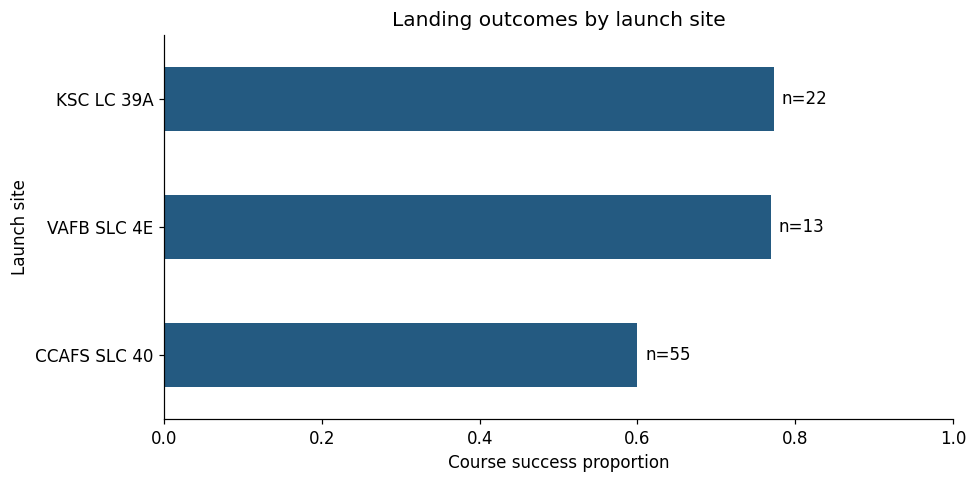

In [2]:
sites = group_summary(df, 'LaunchSite').sort_values('success_rate')
display(sites)
ax = sites.plot.barh(x='LaunchSite', y='success_rate', color='#245a81', legend=False)
ax.set(xlim=(0,1), xlabel='Course success proportion', ylabel='Launch site', title='Landing outcomes by launch site')
for i, row in enumerate(sites.itertuples()): ax.text(row.success_rate+0.01, i, f'n={row.launches}', va='center')
plt.tight_layout(); plt.show()

### Yearly rates and observation counts
A changing mix of rockets, missions, and landing attempts can explain associations; these charts do not isolate a site or year effect.

,Year,launches,successes,success_rate
0,2010,1,0,0.000000
1,2012,1,0,0.000000
2,2013,3,0,0.000000
3,2014,6,2,0.333333
4,2015,6,2,0.333333
5,2016,8,5,0.625000
6,2017,18,15,0.833333
7,2018,18,11,0.611111
8,2019,10,9,0.900000
9,2020,19,16,0.842105


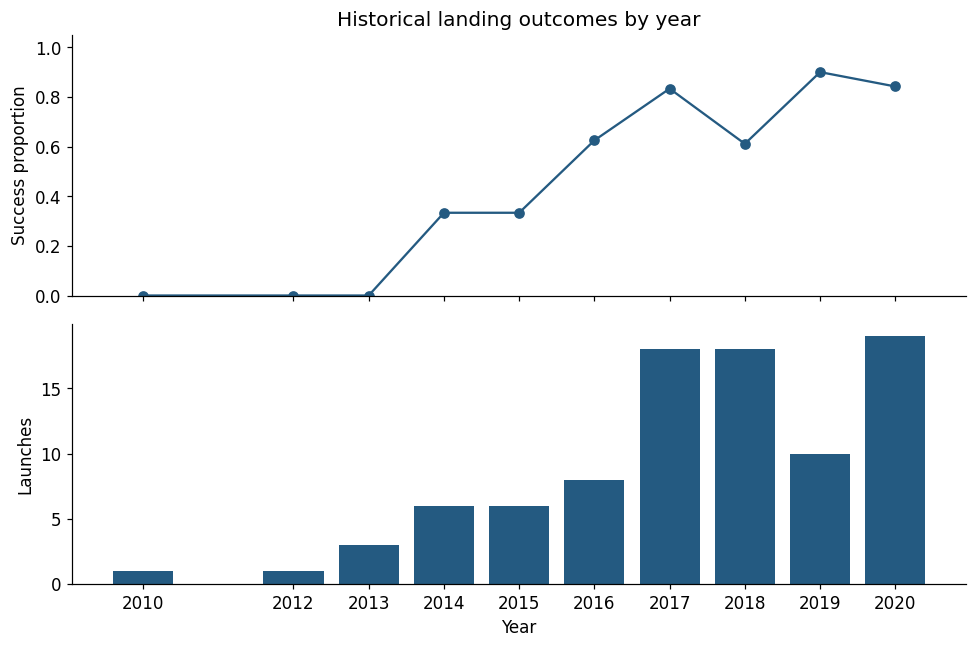

In [3]:
yearly = group_summary(df, 'Year')
display(yearly)
fig, axes = plt.subplots(2,1,figsize=(9,6),sharex=True)
axes[0].plot(yearly.Year, yearly.success_rate, marker='o', color='#245a81')
axes[0].set(ylabel='Success proportion', ylim=(0,1.05), title='Historical landing outcomes by year')
axes[1].bar(yearly.Year, yearly.launches, color='#245a81')
axes[1].set(xlabel='Year', ylabel='Launches')
axes[1].set_xticks(yearly.Year)
plt.tight_layout(); plt.show()

### Payload mass and target
Some payload values were mean-imputed by the course upstream. Treat the pattern as descriptive, not an unbiased missingness analysis.

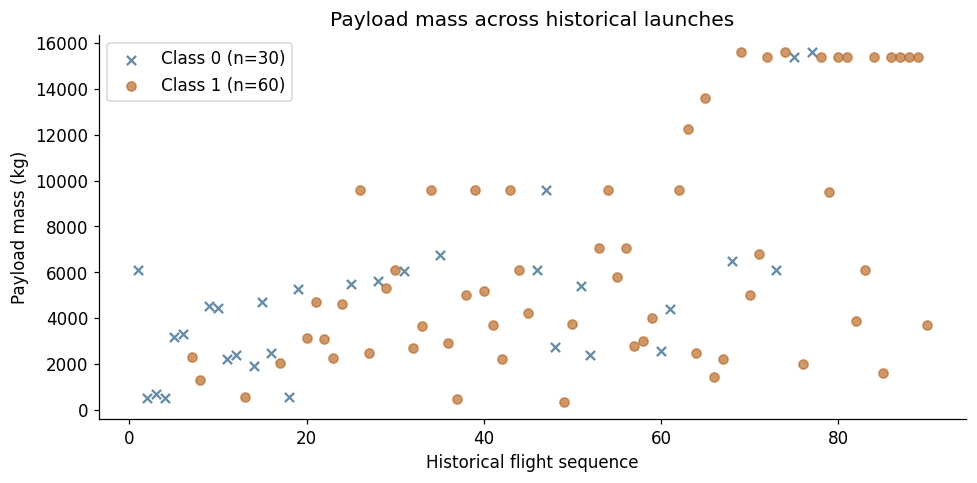

In [4]:
fig, ax = plt.subplots()
for label, marker in [(0,'x'),(1,'o')]:
    subset = df[df.Class == label]
    ax.scatter(subset.FlightNumber, subset.PayloadMass, marker=marker, color={0:'#245a81',1:'#ba6c2d'}[label], alpha=.7, label=f'Class {label} (n={len(subset)})')
ax.set(xlabel='Historical flight sequence', ylabel='Payload mass (kg)', title='Payload mass across historical launches')
ax.legend(); plt.tight_layout(); plt.show()

### Orbit summary

In [5]:
display(group_summary(df, 'Orbit').sort_values('launches', ascending=False))

,Orbit,launches,successes,success_rate
2,GTO,27,14,0.518519
4,ISS,21,13,0.619048
10,VLEO,14,12,0.857143
7,PO,9,6,0.666667
5,LEO,7,5,0.714286
9,SSO,5,5,1.000000
6,MEO,3,2,0.666667
1,GEO,1,1,1.000000
0,ES-L1,1,1,1.000000
3,HEO,1,1,1.000000


## Takeaways
See the displayed tables for exact denominators. Site, orbit, payload, and era are confounded; small groups do not support stable rankings or causal claims. Future launch performance cannot be inferred directly from historical aggregate rates.